<img src="https://drive.google.com/uc?export=view&id=1e7ctPi8O3bTQoLZaO9ZZjwGr2r8Z93RS" width="100%">

# **Entendimiento y Preparación del Corpus**
---



## **0. Integrantes del equipo de trabajo**
---

Nombres completos de los integrantes del equipo de trabajo:


1. Jhon Anderson Bermudez Hurtado
2. Juan Carlos Andrade Unigarro
3. Natalia Patricia Remolina Rodriguez


Durante la segunda fase de entendimiento de los datos buscaremos recopilar, explorar y analizar los datos disponibles para evaluar su calidad, estructura y relevancia para los objetivos del proyecto. Cumpliendo con el cronograma establecido en el diagrama de Gantt para la semana 4.

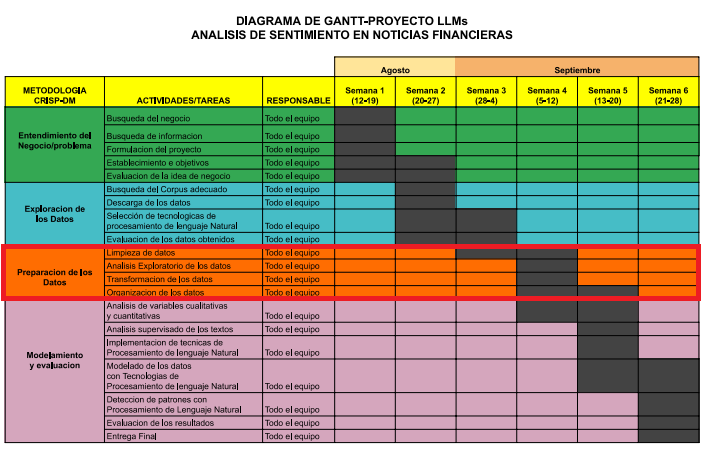

En esta fase, utilizaremos **spaCy** y **Textstat**. *SpaCy* es una biblioteca de Python de código abierto, ampliamente reconocida por su eficiencia y popularidad en el procesamiento de lenguaje natural (PLN). Está diseñada para ser fácil de usar y, al mismo tiempo, altamente potente, ofreciendo tanto enfoques clásicos como modelos avanzados para tareas como la limpieza de textos, la representación de tokens y la detección de idiomas, entre otras funcionalidades. Por otro lado, *Textstat* es un paquete especializado en el análisis de la legibilidad de textos. En otras palabras, permite evaluar la facilidad o dificultad de comprensión de un texto para un lector promedio.


<center>
  <img src="https://drive.google.com/uc?export=view&id=1_ORD5UUaFb1aMgx241KBUstNL7A8Vxj_" width="100%" alt="Spicy - Textstat">
</center>
  
  
  


In [1]:
%%capture
#Instalación de paquetes
!pip install spacy spacy-langdetect
!pip install textstat
!pip install unidecode

In [2]:
#Importacion de librerias
import pandas as pd
import numpy as np
import sys
import textstat
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import spacy
import re
from unidecode import unidecode
from spacy.language import Language
from spacy_langdetect import LanguageDetector

De manera análoga a la guía de desarrollo configuraremos la librería spaCy. Dado que utilizaremos un corpus en español, instalaremos y utilizaremos el modelo de idioma correspondiente `es_core_news_sm`.

Adicionalmente, configuraremos un *pipeline* personalizado para la detección de idioma. Esto nos permitirá identificar textos en el idioma adecuado, permitiéndonos homogeneizar el conjunto de datos.

In [3]:
#Configurar modelo de lenguaje
spacy.cli.download("es_core_news_sm")
nlp = spacy.load("es_core_news_sm")

#Configurar detector de idioma
def get_lang_detector(nlp, name):
    return LanguageDetector()
try:
  Language.factory("language_detector", func=get_lang_detector)
except:
  pass

nlp.add_pipe('language_detector', last=True)

✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


Con el entorno configurado se cargará el conjunto de datos. El Corpus seleccionado para realizar el proyecto será el subconjunto datos en español del dataset *Multilingual Financial Sentiment* disponible en *Hugging Face*, el cual es un conjunto de datos de 39.829 oraciones de noticias financieras, anotadas con etiquetas de sentimiento en 7 idiomas y recopiladas de más de 80 fuentes de noticias financieras de todo el mundo.

Cada registro del corpus contiene un texto financiero y una etiqueta de sentimiento asociada. Las categorías disponibles son:

* Positive: textos cuya orientación financiera es positiva.
* Neutral: textos que no presentan una orientación positiva o negativa claramente predominante.
* Negative: textos cuya orientación financiera es negativa.

Este se encuentra de forma libre a través de la plataforma de *Hugging Face*, por medio del siguiente enlace: https://huggingface.co/datasets/Kenpache/multilingual-financial-sentiment

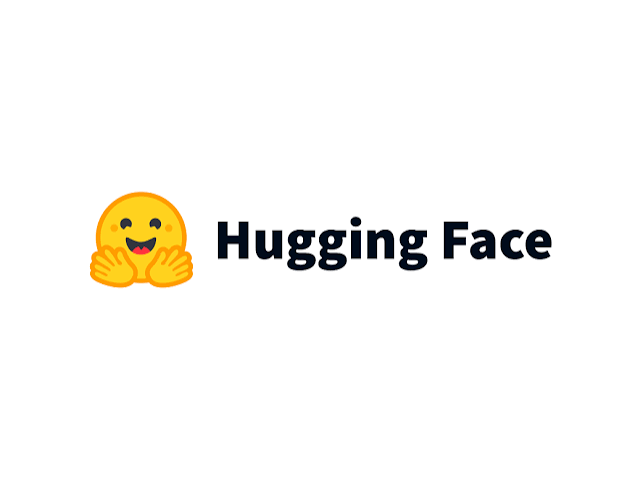

In [4]:
#Importar dataset desde Hugging Face
import pandas as pd

data = pd.read_csv("hf://datasets/Kenpache/multilingual-financial-sentiment/all_languages_clean.csv")
print(data.head())

                                            sentence     label source language
0  Property Play covers new and evolving opportun...   neutral   cnbc       en
1  The costs can be so high that most experts sug...  negative   cnbc       en
2              Terms of the deal were not disclosed.   neutral   cnbc       en
3  "This program grew so dramatically last year, ...  positive   cnbc       en
4  Following the acquisition, 85 employees from D...   neutral   cnbc       en


## **1. Análisis Exploratorio de los Textos**
---

El objetivo de esta sección es caracterizar de forma reproducible el corpus que se utilizará
en el proyecto de análisis de sentimiento de noticias económicas. Además de describir el
dataset completo, se delimita el subconjunto en español y se evalúan su calidad, distribución,
variables disponibles y posibles relaciones o redundancias.

Se trabajará con cuatro preguntas centrales:

1. ¿Cuál es el tamaño, composición e idioma del corpus?
2. ¿Qué problemas de calidad presentan los textos?
3. ¿Cómo se distribuyen la variable objetivo y las variables auxiliares?
4. ¿Existen asociaciones o redundancias que deban considerarse antes del modelado?


### **1.1. Resumen General de los Textos**
---

En esta etapa se responde:

- ¿Cuántos documentos contiene el corpus?
- ¿Cuántas variables tiene?
- ¿Qué tamaño aproximado ocupa en memoria?
- ¿Cómo se distribuyen los idiomas?
- ¿Cuántos documentos corresponden al español?
- ¿De qué fuentes proceden las noticias?
- ¿Existen textos duplicados o grupos naturales de documentos relacionados?

En este proyecto, cada fila representa un titular de noticia económica. Por tanto, las relaciones entre documentos se estudiarán
principalmente a través de su `source`, `language`, `label` y  `sentence`.


In [5]:
# Resumen estructural del dataset completo
n_documentos = data.shape[0]
n_variables = data.shape[1]
memoria_mb = data.memory_usage(deep=True).sum() / (1024 ** 2)

overview = pd.DataFrame({
    'indicador': [
        'Número de documentos',
        'Número de variables',
        'Memoria aproximada (MB)',
        'Textos únicos',
        'Textos duplicados exactos'
    ],
    'valor': [
        n_documentos,
        n_variables,
        round(memoria_mb, 2),
        data['sentence'].nunique(dropna=False),
        int(data.duplicated(subset=['sentence']).sum())
    ]
})

display(overview)
display(data.head())


,indicador,valor
0,Número de documentos,39829.00
1,Número de variables,4.00
2,Memoria aproximada (MB),15.35
3,Textos únicos,39828.00
4,Textos duplicados exactos,1.00


,sentence,label,source,language
0,Property Play covers new and evolving opportun...,neutral,cnbc,en
1,The costs can be so high that most experts sug...,negative,cnbc,en
2,Terms of the deal were not disclosed.,neutral,cnbc,en
3,"""This program grew so dramatically last year, ...",positive,cnbc,en
4,"Following the acquisition, 85 employees from D...",neutral,cnbc,en


#### **Distribución por idioma**

El dataset ya incluye la variable `language`; por ello, esta columna constituye la fuente
principal para cuantificar la composición lingüística. Esto es más eficiente que ejecutar un
detector de idioma sobre las casi cuarenta mil filas únicamente para reconstruir una información
que ya está disponible en los metadatos.

La detección automática de idioma puede utilizarse posteriormente como **validación adicional**
sobre una muestra o sobre el subconjunto español, pero no como sustituto innecesario de la
variable proporcionada por el dataset.


,conteo,porcentaje
language,,
ja,8287,20.81
zh,7930,19.91
es,7125,17.89
en,6887,17.29
de,5023,12.61
fr,3935,9.88
ar,642,1.61


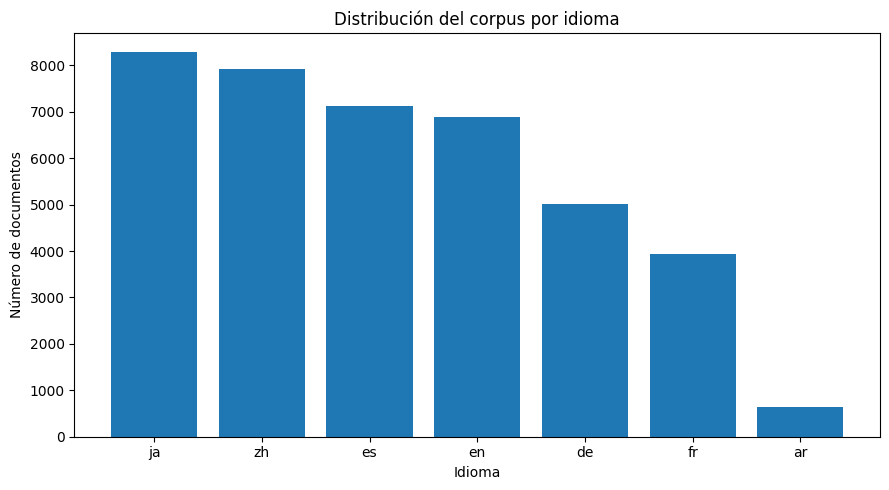

In [6]:
# Distribución de idiomas declarados en el dataset
language_distribution = (
    data['language']
    .value_counts(dropna=False)
    .rename_axis('language')
    .to_frame('conteo')
)

language_distribution['porcentaje'] = (
    100 * language_distribution['conteo'] / language_distribution['conteo'].sum()
).round(2)

display(language_distribution)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(language_distribution.index.astype(str), language_distribution['conteo'])
ax.set_title('Distribución del corpus por idioma')
ax.set_xlabel('Idioma')
ax.set_ylabel('Número de documentos')
plt.tight_layout()
plt.show()


En la siguiente imagen se evidenciaa los diferentes idiomas del dataset, extraido diectamente de la pagina hugging face:


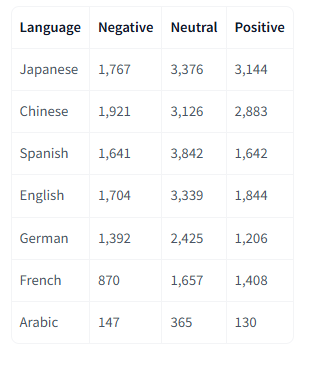

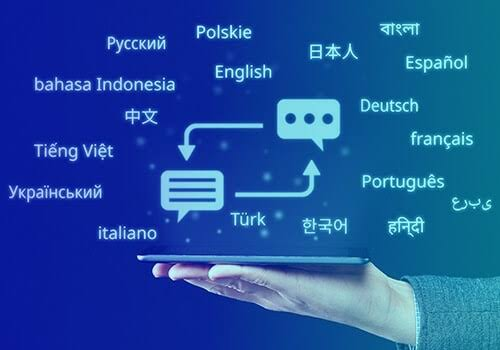

#### **Delimitación del corpus en español**

Dado que el proyecto se centrará en noticias económicas escritas en español, a partir de este
punto se trabaja con `language == "es"`. Se crea una copia explícita para evitar modificaciones
accidentales sobre el dataset completo.


In [7]:
# Corpus de trabajo: únicamente documentos etiquetados como español
es_data = data.loc[data['language'].eq('es')].copy()

spanish_summary = pd.DataFrame({
    'indicador': [
        'Documentos en español',
        'Porcentaje del dataset total',
        'Fuentes distintas',
        'Etiquetas distintas',
        'Textos únicos',
        'Duplicados exactos de sentence'
    ],
    'valor': [
        len(es_data),
        round(100 * len(es_data) / len(data), 2),
        es_data['source'].nunique(dropna=True),
        es_data['label'].nunique(dropna=True),
        es_data['sentence'].nunique(dropna=False),
        int(es_data.duplicated(subset=['sentence']).sum())
    ]
})

display(spanish_summary)
display(es_data.head())


,indicador,valor
0,Documentos en español,7125.00
1,Porcentaje del dataset total,17.89
2,Fuentes distintas,14.00
3,Etiquetas distintas,3.00
4,Textos únicos,7125.00
5,Duplicados exactos de sentence,0.00


,sentence,label,source,language
32062,- Isdin abrirá un centro logístico de 22.000 m...,positive,expansion_empresas,es
32063,MiiN Cosmetics dispara los ingresos y pisa el ...,positive,expansion_empresas,es
32064,La subida del volumen de negocio coincidió con...,positive,expansion_empresas,es
32065,La compańía barcelonesa entró el ańo pasado en...,neutral,expansion_empresas,es
32066,MiiN también abrió en 2025 un centro logístico...,positive,expansion_empresas,es


#### **Relación entre documentos: fuente de procedencia**

En este corpus la variable `source` permite identificar un agrupamiento natural: distintas
noticias provienen de una misma fuente. Esta relación es relevante porque una fuente puede
tener estilo editorial, vocabulario o distribución de etiquetas particulares. Por ello se
describe su representación dentro del corpus en español.


,conteo,porcentaje
source,,
estrategias_inversion,1758,24.67
expansion_empresas,951,13.35
expansion,849,11.92
elconfidencial,773,10.85
bloomberg_linea,530,7.44
efe_economia,508,7.13
cinco_dias,438,6.15
investing_es,337,4.73
infobae_economia,249,3.49


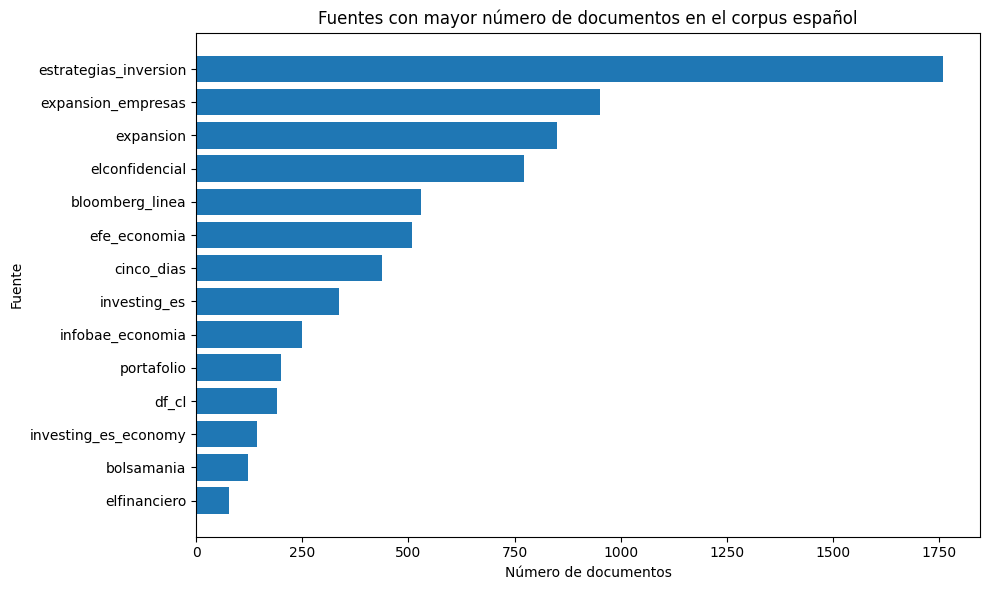

In [8]:
source_distribution = (
    es_data['source']
    .value_counts(dropna=False)
    .rename_axis('source')
    .to_frame('conteo')
)
source_distribution['porcentaje'] = (
    100 * source_distribution['conteo'] / source_distribution['conteo'].sum()
).round(2)

display(source_distribution)

top_sources = source_distribution.head(15).sort_values('conteo')

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_sources.index.astype(str), top_sources['conteo'])
ax.set_title('Fuentes con mayor número de documentos en el corpus español')
ax.set_xlabel('Número de documentos')
ax.set_ylabel('Fuente')
plt.tight_layout()
plt.show()


#### **Resumen del corpus**

El siguiente bloque consolida la información básica que debe quedar documentada antes de
realizar cualquier limpieza. Los resultados se calculan directamente a partir de los datos
para evitar conclusiones escritas que puedan quedar desactualizadas si el dataset cambia.


In [9]:
corpus_summary = pd.DataFrame({
    'métrica': [
        'Documentos totales',
        'Documentos en español',
        'Variables',
        'Idiomas del dataset completo',
        'Fuentes del corpus español',
        'Clases de sentimiento',
        'Duplicados de texto en español'
    ],
    'valor': [
        len(data),
        len(es_data),
        data.shape[1],
        data['language'].nunique(dropna=True),
        es_data['source'].nunique(dropna=True),
        es_data['label'].nunique(dropna=True),
        int(es_data.duplicated(subset=['sentence']).sum())
    ]
})

display(corpus_summary)


,métrica,valor
0,Documentos totales,39829
1,Documentos en español,7125
2,Variables,4
3,Idiomas del dataset completo,7
4,Fuentes del corpus español,14
5,Clases de sentimiento,3
6,Duplicados de texto en español,0


### **1.2. Resumen de la Calidad de los Textos**
---

La calidad del corpus se evalúa en varios niveles:

1. **Completitud:** valores nulos, textos vacíos o compuestos solo por espacios.
2. **Duplicación:** textos o filas repetidas.
3. **Consistencia de etiquetas:** valores esperados en `label` y `language`.
4. **Codificación y grafía:** caracteres de reemplazo, caracteres de control y patrones
   potencialmente anómalos.
5. **Características textuales:** longitud y legibilidad.

La legibilidad se utilizará como **métrica descriptiva**, no como criterio automático para
eliminar noticias. En textos financieros, una redacción técnicamente compleja puede ser válida;
eliminarla por ser "difícil de leer" podría sesgar el corpus.


#### **1.2.1. Valores nulos, documentos vacíos y duplicados**

`isnull()` permite detectar valores ausentes, pero no identifica cadenas vacías como `""`
o `"   "`. Por ello se verifican ambas situaciones explícitamente.


In [10]:
# Auditoría básica de calidad del corpus español
quality_basic = pd.DataFrame(index=es_data.columns)

quality_basic['nulos'] = es_data.isna().sum()
quality_basic['porcentaje_nulos'] = (
    100 * quality_basic['nulos'] / len(es_data)
).round(2)

# Solo tiene sentido buscar cadenas vacías en columnas de texto.
for col in ['sentence', 'label', 'source', 'language']:
    s = es_data[col].fillna('').astype(str)
    quality_basic.loc[col, 'vacios_o_espacios'] = int(s.str.strip().eq('').sum())

display(quality_basic)

print('Duplicados exactos de sentence:',
      int(es_data.duplicated(subset=['sentence']).sum()))
print('Filas completamente duplicadas:',
      int(es_data.duplicated().sum()))


,nulos,porcentaje_nulos,vacios_o_espacios
sentence,0,0.0,0.0
label,0,0.0,0.0
source,0,0.0,0.0
language,0,0.0,0.0


Duplicados exactos de sentence: 0
Filas completamente duplicadas: 0


#### **1.2.2. Consistencia de las etiquetas**

Para el problema propuesto se esperan tres clases de sentimiento:
`negative`, `neutral` y `positive`. También se valida que el subconjunto mantenga
`language == "es"`.


In [11]:
expected_labels = {'negative', 'neutral', 'positive'}

observed_labels = set(
    es_data['label'].dropna().astype(str).str.strip().str.lower().unique()
)

unexpected_labels = sorted(observed_labels - expected_labels)
unexpected_languages = sorted(
    set(es_data['language'].dropna().astype(str).unique()) - {'es'}
)

print('Etiquetas observadas:', sorted(observed_labels))
print('Etiquetas no esperadas:', unexpected_labels)
print('Idiomas no esperados dentro de es_data:', unexpected_languages)


Etiquetas observadas: ['negative', 'neutral', 'positive']
Etiquetas no esperadas: []
Idiomas no esperados dentro de es_data: []


#### **1.2.3. Indicios de problemas de codificación**

Los caracteres Unicode válidos no son necesariamente errores. Por lo cual:

Se buscan:

- `�`: carácter de reemplazo Unicode, indicador fuerte de pérdida durante una decodificación;
- `Ã`, `Â`, `â`: patrones comunes de *mojibake*;
- `ń`: carácter válido en otros idiomas, pero atípico en español y observado en algunos
  fragmentos del corpus;
- caracteres de control no imprimibles;
- posibles etiquetas HTML residuales.

In [12]:
sentence_text = es_data['sentence'].fillna('').astype(str)

encoding_checks = pd.Series({
    'caracter_reemplazo_�': sentence_text.str.contains('\uFFFD', regex=False).sum(),
    'posible_mojibake_Ã': sentence_text.str.contains('Ã', regex=False).sum(),
    'posible_mojibake_Â': sentence_text.str.contains('Â', regex=False).sum(),
    'posible_mojibake_â': sentence_text.str.contains('â', regex=False).sum(),
    'caracter_atipico_ń': sentence_text.str.contains('ń', regex=False).sum(),
    'caracteres_control': sentence_text.str.contains(
        r'[\x00-\x08\x0B\x0C\x0E-\x1F]', regex=True
    ).sum(),
    'posible_html': sentence_text.str.contains(r'<[^>]+>', regex=True).sum()
}).astype(int)

display(encoding_checks.to_frame('conteo'))

encoding_pattern = r'�|Ã|Â|â|ń|[\x00-\x08\x0B\x0C\x0E-\x1F]|<[^>]+>'
encoding_flag = sentence_text.str.contains(encoding_pattern, regex=True)

print('Documentos con alguna bandera de codificación/grafía:',
      int(encoding_flag.sum()))

if encoding_flag.any():
    display(
        es_data.loc[encoding_flag, ['sentence', 'label', 'source']]
        .head(10)
    )


,conteo
caracter_reemplazo_�,120
posible_mojibake_Ã,0
posible_mojibake_Â,0
posible_mojibake_â,2
caracter_atipico_ń,313
caracteres_control,0
posible_html,0


Documentos con alguna bandera de codificación/grafía: 435


,sentence,label,source
32062,- Isdin abrirá un centro logístico de 22.000 m...,positive,expansion_empresas
32064,La subida del volumen de negocio coincidió con...,positive,expansion_empresas
32065,La compańía barcelonesa entró el ańo pasado en...,neutral,expansion_empresas
32066,MiiN también abrió en 2025 un centro logístico...,positive,expansion_empresas
32067,La empresa cerró el ańo con un ebitda positivo...,positive,expansion_empresas
32068,La compańía participada por Barlon Capital pre...,positive,expansion_empresas
32071,La compańía argumenta que en Espańa existe un ...,positive,expansion_empresas
32072,"""La reconversión de las plantas industriales d...",neutral,expansion_empresas
32073,Contactos entre Indra y SeatCabe recordar que ...,neutral,expansion_empresas
32074,En el caso de Indra buscaría aprovechar la cap...,positive,expansion_empresas


#### **1.2.4. Legibilidad y características de calidad**

Se conserva el índice de Fernández-Huerta como una descripción de complejidad lingüística.
No se interpreta como una medida de "veracidad" ni como un filtro de sentimiento.

Además se calcula una medida simple de proporción de tokens alfabéticos para detectar
fragmentos dominados por símbolos o ruido. Esta métrica tampoco elimina registros por sí sola;
sirve para inspeccionar extremos.


,count,mean,std,min,5%,25%,50%,75%,95%,max
fernandez_huerta,7125.0,72.079421,17.871260,4.297143,42.202182,60.240000,72.950000,84.249565,100.165455,137.44
proporcion_tokens_alfanumericos,7125.0,0.851480,0.108373,0.463415,0.562500,0.833333,0.882353,0.918919,0.954545,1.00


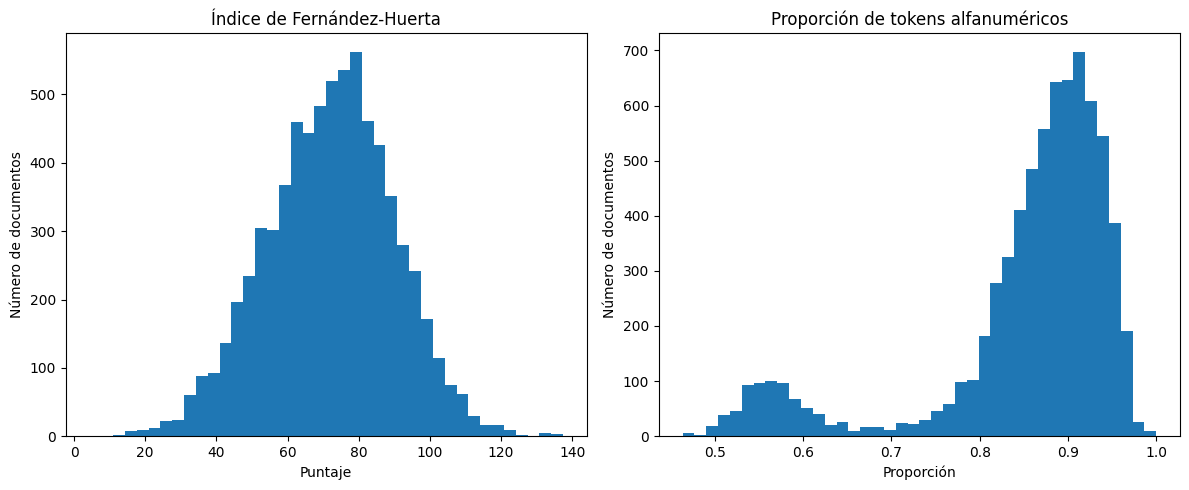

In [13]:
def alphabetic_token_ratio(text):
    doc = nlp(str(text))
    tokens = [t for t in doc if not t.is_space]
    if not tokens:
        return 0.0
    return np.mean([t.is_alpha or t.like_num for t in tokens])

# Métricas descriptivas de calidad
reading_quality = es_data['sentence'].astype(str).map(textstat.fernandez_huerta)
alpha_token_ratio = es_data['sentence'].astype(str).map(alphabetic_token_ratio)

quality_metrics = pd.DataFrame({
    'fernandez_huerta': reading_quality,
    'proporcion_tokens_alfanumericos': alpha_token_ratio
})

display(
    quality_metrics.describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    ).T
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(reading_quality.dropna(), bins=40)
axes[0].set_title('Índice de Fernández-Huerta')
axes[0].set_xlabel('Puntaje')
axes[0].set_ylabel('Número de documentos')

axes[1].hist(alpha_token_ratio.dropna(), bins=40)
axes[1].set_title('Proporción de tokens alfanuméricos')
axes[1].set_xlabel('Proporción')
axes[1].set_ylabel('Número de documentos')

plt.tight_layout()
plt.show()


#### **1.2.5. Construcción del corpus para las etapas siguientes**

Para no introducir sesgos por un umbral arbitrario de legibilidad, el filtrado se limita a
condiciones objetivas:

- texto no nulo y no vacío;
- `label` perteneciente a las tres clases previstas;
- idioma declarado como español;
- eliminación de duplicados exactos de `sentence`.

Los documentos con indicios de codificación se **conservan**, pero se marcan para que el
preprocesamiento pueda normalizar lo que sea recuperable sin inventar caracteres.


In [14]:
# Máscaras de calidad reproducibles
sentence_clean_mask = (
    es_data['sentence'].notna()
    & es_data['sentence'].astype(str).str.strip().ne('')
)

label_clean_mask = (
    es_data['label']
    .fillna('')
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(expected_labels)
)

language_clean_mask = es_data['language'].eq('es')

data_corrected = (
    es_data.loc[
        sentence_clean_mask & label_clean_mask & language_clean_mask
    ]
    .copy()
)

# Normalización mínima de las etiquetas antes de continuar.
data_corrected['label'] = (
    data_corrected['label']
    .astype(str)
    .str.strip()
    .str.lower()
)

before_dedup = len(data_corrected)
data_corrected = data_corrected.drop_duplicates(
    subset=['sentence'],
    keep='first'
).copy()

removed_duplicates = before_dedup - len(data_corrected)

# Bandera informativa; no elimina documentos.
data_corrected['encoding_flag'] = (
    data_corrected['sentence']
    .fillna('')
    .astype(str)
    .str.contains(encoding_pattern, regex=True)
)

quality_filter_summary = pd.DataFrame({
    'indicador': [
        'Documentos españoles iniciales',
        'Documentos válidos después de filtros objetivos',
        'Duplicados eliminados',
        'Documentos conservados con bandera de codificación',
        'Porcentaje de conservación'
    ],
    'valor': [
        len(es_data),
        len(data_corrected),
        removed_duplicates,
        int(data_corrected['encoding_flag'].sum()),
        round(100 * len(data_corrected) / len(es_data), 2)
    ]
})

display(quality_filter_summary)


,indicador,valor
0,Documentos españoles iniciales,7125.0
1,Documentos válidos después de filtros objetivos,7125.0
2,Duplicados eliminados,0.0
3,Documentos conservados con bandera de codifica...,435.0
4,Porcentaje de conservación,100.0


Como se puede apreciar en las etapas anteriores el corpus que continúa en el EDA evita eliminar noticias por
complejidad lingüística. De esta forma se reduce el riesgo de alterar artificialmente la
distribución de fuentes o sentimientos. Las métricas de legibilidad se conservan como
caracterización descriptiva y los posibles artefactos de codificación quedan señalados
para el preprocesamiento.


### **1.3. Tipos de Variables**
---

El dataset contiene cuatro variables originales:

- `sentence`: texto de entrada;
- `label`: sentimiento objetivo;
- `source`: fuente de procedencia;
- `language`: idioma declarado.

Después del filtro al español, `language` deja de aportar variabilidad. `source` sí contiene
información útil para auditar sesgos de origen, pero su uso directo como predictor debe
justificarse: un modelo podría aprender patrones editoriales de una fuente en lugar del
sentimiento expresado en el texto.


In [15]:
variable_catalog = pd.DataFrame([
    {
        'variable': 'sentence',
        'tipo': 'Texto no estructurado',
        'rol': 'Predictor principal',
        'decision': 'Conservar',
        'justificacion': 'Contiene el contenido lingüístico sobre el cual se clasificará el sentimiento.'
    },
    {
        'variable': 'label',
        'tipo': 'Categórica nominal (3 clases)',
        'rol': 'Variable objetivo',
        'decision': 'Conservar',
        'justificacion': 'Define negative, neutral y positive.'
    },
    {
        'variable': 'source',
        'tipo': 'Categórica nominal',
        'rol': 'Metadato / variable de auditoría',
        'decision': 'No usar en la línea base',
        'justificacion': 'Puede revelar sesgos editoriales o de dominio y producir dependencia de la fuente.'
    },
    {
        'variable': 'language',
        'tipo': 'Categórica nominal',
        'rol': 'Filtro',
        'decision': 'Excluir del modelo en español',
        'justificacion': 'Después del filtro es constante (es) y no aporta capacidad discriminativa.'
    },
    {
        'variable': 'encoding_flag',
        'tipo': 'Booleana',
        'rol': 'Control de calidad',
        'decision': 'No usar como predictor inicialmente',
        'justificacion': 'Sirve para auditar textos con posibles artefactos de codificación.'
    }
])

display(variable_catalog)


,variable,tipo,rol,decision,justificacion
0,sentence,Texto no estructurado,Predictor principal,Conservar,Contiene el contenido lingüístico sobre el cua...
1,label,Categórica nominal (3 clases),Variable objetivo,Conservar,"Define negative, neutral y positive."
2,source,Categórica nominal,Metadato / variable de auditoría,No usar en la línea base,Puede revelar sesgos editoriales o de dominio ...
3,language,Categórica nominal,Filtro,Excluir del modelo en español,Después del filtro es constante (es) y no apor...
4,encoding_flag,Booleana,Control de calidad,No usar como predictor inicialmente,Sirve para auditar textos con posibles artefac...


#### **Distribución de la variable objetivo**

`label` se modelará como una **clasificación multiclase** con tres categorías. Aunque
`negative`, `neutral` y `positive` tienen una interpretación semántica ordenable, en esta
fase se tratan como clases nominales para no imponer una distancia numérica artificial entre ellas.

Además del gráfico de barras se cuantifica el desbalance mediante la razón entre la clase
más frecuente y la menos frecuente.


,conteo,porcentaje
label,,
negative,1641,23.03
neutral,3842,53.92
positive,1642,23.05


Relación clase mayoritaria / clase minoritaria: 2.34:1


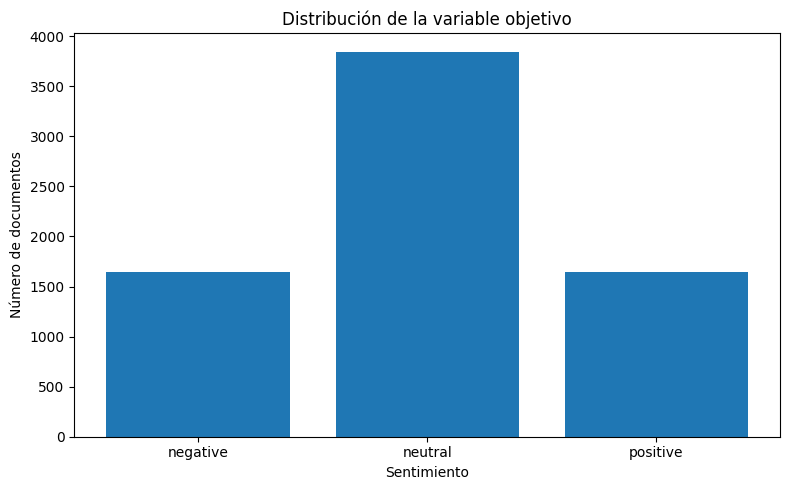

In [16]:
variable_obj = data_corrected['label']

class_distribution = (
    variable_obj.value_counts()
    .reindex(['negative', 'neutral', 'positive'])
    .fillna(0)
    .astype(int)
    .rename_axis('label')
    .to_frame('conteo')
)

class_distribution['porcentaje'] = (
    100 * class_distribution['conteo'] / class_distribution['conteo'].sum()
).round(2)

display(class_distribution)

max_class = int(class_distribution['conteo'].max())
min_class = int(class_distribution['conteo'].min())
imbalance_ratio = max_class / min_class if min_class > 0 else np.inf

print(f'Relación clase mayoritaria / clase minoritaria: {imbalance_ratio:.2f}:1')

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(class_distribution.index, class_distribution['conteo'])
ax.set_title('Distribución de la variable objetivo')
ax.set_xlabel('Sentimiento')
ax.set_ylabel('Número de documentos')
plt.tight_layout()
plt.show()


La interpretación del desbalance debe basarse en los valores calculados y no únicamente
en la inspección visual. Si la clase `neutral` concentra sustancialmente más ejemplos que las
clases `positive` y `negative`, las métricas de evaluación posteriores deberían incluir
medidas robustas al desbalance, como **F1 macro**, además de métricas globales.

No se aplicará sobremuestreo ni ponderación en esta fase. Esas decisiones pertenecen al
modelado y, si se usan, deberán calcularse únicamente sobre el conjunto de entrenamiento.


#### **Longitud y diversidad léxica de los documentos**

Se caracterizan los textos mediante:

- número de caracteres;
- número de palabras;
- *Type-Token Ratio* (TTR), proporción de palabras únicas respecto al total.

El TTR se interpreta con cautela porque depende de la longitud: textos cortos tienden a
obtener valores altos con mayor facilidad.


,count,mean,std,min,5%,25%,50%,75%,95%,max
caracteres,7125.0,207.578667,87.824086,29.0,84.000000,143.000000,198.000000,258.000000,375.8,527.0
palabras,7125.0,33.088140,13.827041,5.0,14.000000,23.000000,31.000000,42.000000,59.0,80.0
TTR,7125.0,0.866339,0.080628,0.5,0.730769,0.809524,0.869565,0.928571,1.0,1.0


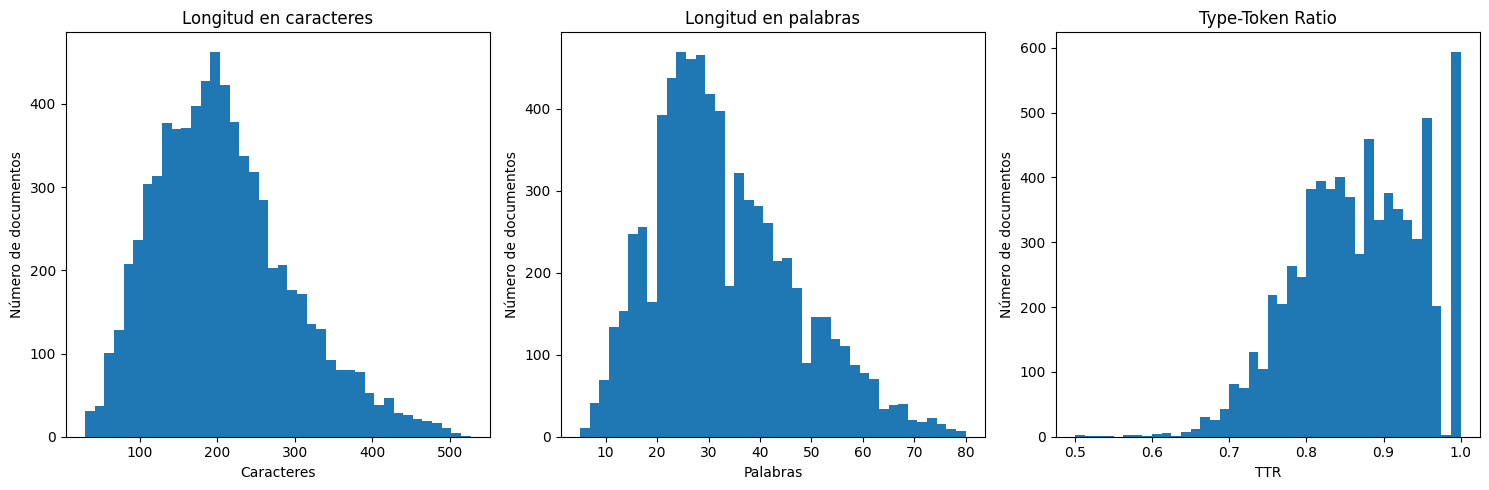

In [17]:
text_length_chars = data_corrected['sentence'].astype(str).map(len)
text_length_words = data_corrected['sentence'].astype(str).map(
    lambda x: len(x.split())
)

def type_token_ratio(text):
    tokens = [t.lower() for t in str(text).split() if t.strip()]
    return len(set(tokens)) / len(tokens) if tokens else 0.0

text_ttr = data_corrected['sentence'].map(type_token_ratio)

text_stats = pd.DataFrame({
    'caracteres': text_length_chars,
    'palabras': text_length_words,
    'TTR': text_ttr
}, index=data_corrected.index)

display(
    text_stats.describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    ).T
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].hist(text_stats['caracteres'], bins=40)
axes[0].set_title('Longitud en caracteres')
axes[0].set_xlabel('Caracteres')
axes[0].set_ylabel('Número de documentos')

axes[1].hist(text_stats['palabras'], bins=40)
axes[1].set_title('Longitud en palabras')
axes[1].set_xlabel('Palabras')
axes[1].set_ylabel('Número de documentos')

axes[2].hist(text_stats['TTR'], bins=40)
axes[2].set_title('Type-Token Ratio')
axes[2].set_xlabel('TTR')
axes[2].set_ylabel('Número de documentos')

plt.tight_layout()
plt.show()


#### **Análisis descriptivo de `source`**

`source` no se incorpora automáticamente al modelo, pero sí se analiza porque puede revelar
concentración del corpus o diferencias de dominio entre fuentes. Esto es importante para
interpretar correctamente el desempeño futuro del clasificador.


,conteo,porcentaje
source,,
estrategias_inversion,1758,24.67
expansion_empresas,951,13.35
expansion,849,11.92
elconfidencial,773,10.85
bloomberg_linea,530,7.44
efe_economia,508,7.13
cinco_dias,438,6.15
investing_es,337,4.73
infobae_economia,249,3.49


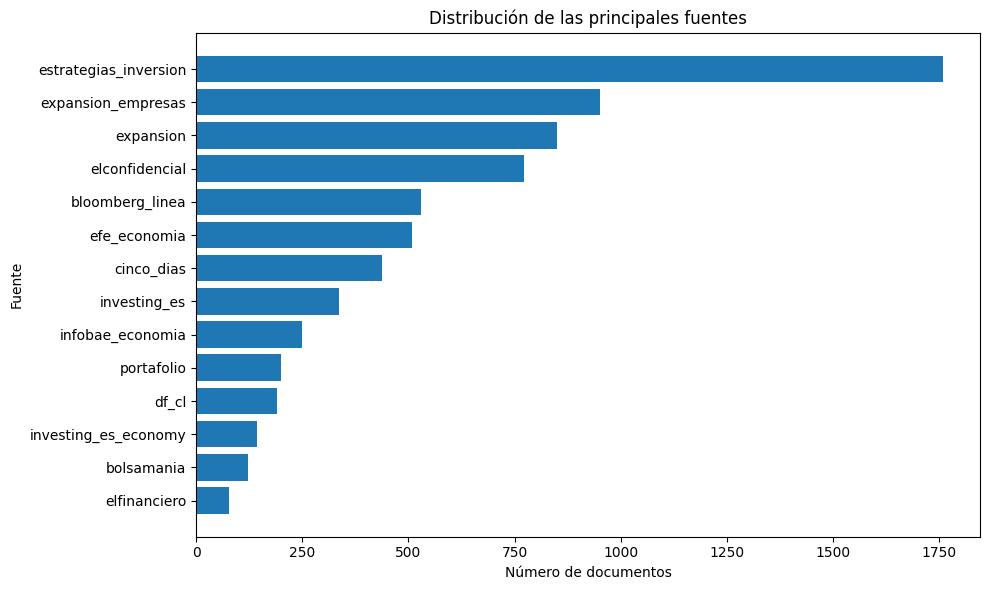

In [18]:
source_stats = (
    data_corrected['source']
    .value_counts(dropna=False)
    .rename_axis('source')
    .to_frame('conteo')
)

source_stats['porcentaje'] = (
    100 * source_stats['conteo'] / source_stats['conteo'].sum()
).round(2)

display(source_stats)

top_sources = source_stats.head(15).sort_values('conteo')

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_sources.index.astype(str), top_sources['conteo'])
ax.set_title('Distribución de las principales fuentes')
ax.set_xlabel('Número de documentos')
ax.set_ylabel('Fuente')
plt.tight_layout()
plt.show()


### **1.4. Relación Entre Variables y Redundancia**
---

Como el dataset contiene principalmente texto y variables categóricas, una matriz de
correlación de Pearson sobre las columnas originales no sería apropiada.

En su lugar se estudian relaciones que sí tienen interpretación:

1. `source` frente a `label`, mediante una tabla de contingencia y el **V de Cramér**;
2. longitud/TTR frente a `label`, mediante estadísticas y diagramas de caja;
3. redundancia entre las medidas numéricas derivadas del texto mediante correlación de Spearman;
4. redundancia estructural de `language`, que es constante una vez filtrado el español.


V de Cramér(source, label): 0.229
p-value del contraste chi-cuadrado: 8.056e-141


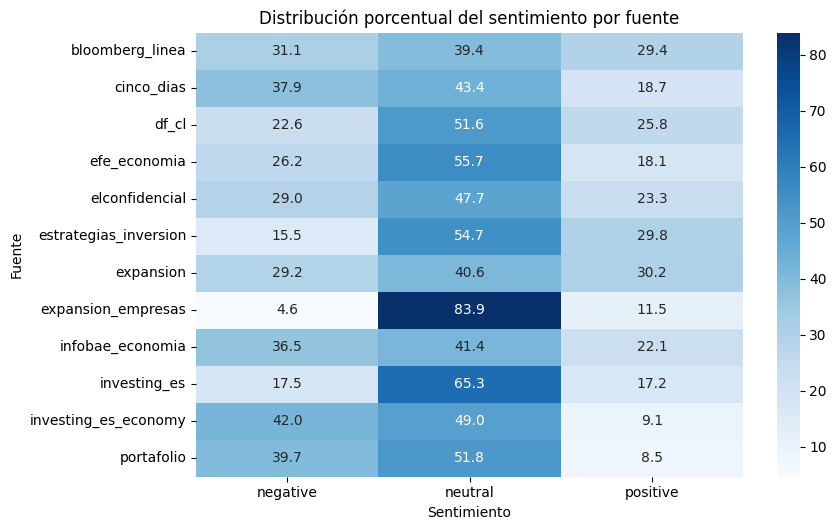

In [19]:
# Asociación entre source y label
from scipy.stats import chi2_contingency

source_label_table = pd.crosstab(
    data_corrected['source'],
    data_corrected['label']
)

source_label_pct = pd.crosstab(
    data_corrected['source'],
    data_corrected['label'],
    normalize='index'
) * 100

# V de Cramér
chi2, p_value, _, _ = chi2_contingency(source_label_table)
n = source_label_table.to_numpy().sum()
min_dim = min(source_label_table.shape) - 1
cramers_v = np.sqrt((chi2 / n) / min_dim) if min_dim > 0 else np.nan

print(f'V de Cramér(source, label): {cramers_v:.3f}')
print(f'p-value del contraste chi-cuadrado: {p_value:.3e}')

# Visualizar solo las fuentes más representadas para mantener legibilidad
top_source_names = (
    data_corrected['source']
    .value_counts()
    .head(12)
    .index
)

heatmap_data = source_label_pct.loc[
    source_label_pct.index.intersection(top_source_names)
]

plt.figure(figsize=(9, max(5, 0.45 * len(heatmap_data))))
sns.heatmap(
    heatmap_data[['negative', 'neutral', 'positive']],
    annot=True,
    fmt='.1f',
    cmap='Blues'
)
plt.title('Distribución porcentual del sentimiento por fuente')
plt.xlabel('Sentimiento')
plt.ylabel('Fuente')
plt.tight_layout()
plt.show()


El V de Cramér resume la intensidad de la asociación entre dos variables categóricas.
El resultado debe interpretarse junto con la tabla y el tamaño de muestra. Una asociación
entre `source` y `label` no implica causalidad, pero sí puede advertir que el corpus contiene
diferencias de distribución entre fuentes.

Esto justifica mantener `source` como variable de **auditoría** y no incluirla de forma
automática como predictor en una primera línea base.


caracteres                         palabras                         \
              count     mean median     std    count    mean median     std   
label                                                                         
negative       1641  212.332  200.0  85.038     1641  35.551   33.0  14.106   
neutral        3842  207.682  200.0  89.690     3842  31.955   29.0  13.549   
positive       1642  202.588  191.0  85.913     1642  33.277   31.0  13.869   

           TTR                       
         count   mean median    std  
label                                
negative  1641  0.848  0.846  0.080  
neutral   3842  0.875  0.882  0.081  
positive  1642  0.863  0.864  0.077

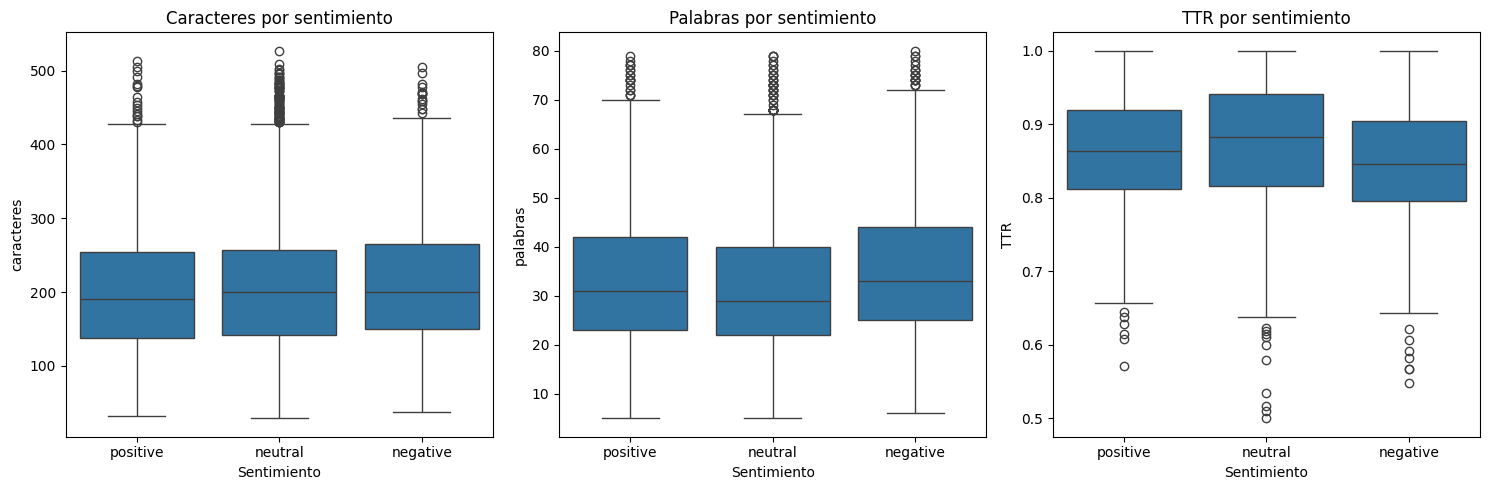

In [20]:
# Relación de características textuales con la clase
analysis_frame = pd.DataFrame({
    'label': data_corrected['label'],
    'caracteres': text_stats['caracteres'],
    'palabras': text_stats['palabras'],
    'TTR': text_stats['TTR']
})

display(
    analysis_frame
    .groupby('label')[['caracteres', 'palabras', 'TTR']]
    .agg(['count', 'mean', 'median', 'std'])
    .round(3)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(data=analysis_frame, x='label', y='caracteres', ax=axes[0])
axes[0].set_title('Caracteres por sentimiento')

sns.boxplot(data=analysis_frame, x='label', y='palabras', ax=axes[1])
axes[1].set_title('Palabras por sentimiento')

sns.boxplot(data=analysis_frame, x='label', y='TTR', ax=axes[2])
axes[2].set_title('TTR por sentimiento')

for ax in axes:
    ax.set_xlabel('Sentimiento')

plt.tight_layout()
plt.show()


#### **Redundancia entre características derivadas**

Las variables `caracteres` y `palabras` miden aspectos muy similares de la extensión del
texto y pueden ser redundantes. Se calcula correlación de Spearman para documentarlo de
forma cuantitativa.


,caracteres,palabras,TTR
caracteres,1.000,0.949,-0.555
palabras,0.949,1.000,-0.681
TTR,-0.555,-0.681,1.000


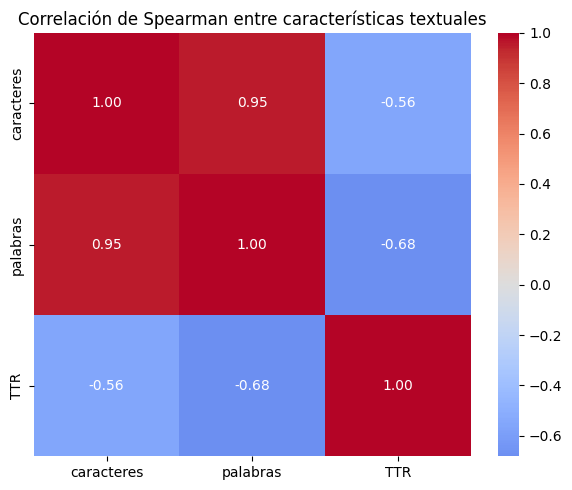

|rho| caracteres-palabras = 0.949
Conclusión: caracteres y palabras son altamente redundantes; para una línea base puede conservarse solo una medida de longitud.
La variable 'language' también es redundante para el modelado del subconjunto español, ya que toma un único valor.


In [21]:
spearman_text = text_stats[['caracteres', 'palabras', 'TTR']].corr(
    method='spearman'
)

display(spearman_text.round(3))

plt.figure(figsize=(6, 5))
sns.heatmap(
    spearman_text,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)
plt.title('Correlación de Spearman entre características textuales')
plt.tight_layout()
plt.show()

length_corr = abs(spearman_text.loc['caracteres', 'palabras'])

print(f'|rho| caracteres-palabras = {length_corr:.3f}')

if length_corr >= 0.90:
    print(
        'Conclusión: caracteres y palabras son altamente redundantes; '
        'para una línea base puede conservarse solo una medida de longitud.'
    )
else:
    print(
        'Conclusión: la redundancia entre caracteres y palabras no supera '
        'el umbral exploratorio de 0.90.'
    )

print(
    "La variable 'language' también es redundante para el modelado del "
    "subconjunto español, ya que toma un único valor."
)


### **Conclusiones del punto 1**

Con este análisis quedan cubiertos de forma explícita:

- dimensión y composición del corpus
- distribución por idioma y delimitación del español
- fuentes de procedencia
- nulos, vacíos, duplicados e indicios de codificación
- legibilidad como métrica descriptiva
- inventario y función de todas las variables
- distribución y desbalance de `label`
- longitud y riqueza léxica
- asociación `source`-`label`
- posibles redundancias antes del modelado.

Estas decisiones permiten pasar a la limpieza con criterios trazables, evitando filtros
arbitrarios que puedan modificar la distribución del sentimiento.


## **2. Limpieza de los Textos**
---

El preprocesamiento debe ser coherente con el objetivo de **clasificar sentimiento en noticias
económicas**. Por esta razón no conviene eliminar indiscriminadamente toda la información que
parece "ruido":

- las **negaciones** (`no`, `nunca`, `sin`, etc.) pueden cambiar el sentimiento;
- los **números, porcentajes y monedas** son informativos en noticias financieras;
- los acentos y caracteres españoles son información lingüística válida.

La estrategia aplicada combina normalización Unicode, tokenización, lematización, filtrado
conservador de *stop words* y preservación de señales financieras mediante marcadores.


### **2.1. Decisiones de preprocesamiento**

Se aplicarán las siguientes transformaciones:

1. **Normalización Unicode NFKC** y eliminación de caracteres de control invisibles.
2. Sustitución del carácter de reemplazo `�` por espacio. No se intenta adivinar el carácter
   perdido.
3. **Tokenización con spaCy**.
4. **Lematización** de palabras alfabéticas.
5. **Minúsculas** manteniendo caracteres propios del español.
6. Eliminación de puntuación y espacios redundantes.
7. Eliminación de *stop words* de forma conservadora.
8. **Preservación de negaciones** aunque spaCy las marque como *stop words*.
9. Normalización de números, porcentajes y monedas mediante los tokens `num`, `pct` y `moneda`.
10. Conservación del texto original en `sentence_original`; el resultado procesado se guarda
    en una nueva columna `sentence_clean`.

No se realiza corrección ortográfica automática, ya que una corrección no supervisada podría
alterar nombres de empresas, productos o entidades económicas.


In [22]:
import unicodedata

# Negaciones relevantes para análisis de sentimiento que NO se eliminan.
NEGATIONS_TO_KEEP = {
    'no', 'nunca', 'jamás', 'jamas', 'sin', 'ni', 'tampoco', 'nadie', 'ninguno', 'ninguna'
}

CURRENCY_SYMBOLS = {'$', '€', '£', '¥', '₩', '₹', '₽', '₺'}

def normalize_unicode_text(text):
    text = unicodedata.normalize('NFKC', str(text))
    text = text.replace('\uFFFD', ' ')   # carácter de reemplazo
    text = text.replace('\u200b', ' ')   # zero-width space
    text = text.replace('\ufeff', ' ')   # BOM / zero-width no-break
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

def preprocess_doc(doc):
    cleaned_tokens = []

    for token in doc:
        raw = token.text.strip()
        lower = raw.lower()

        if not raw or token.is_space:
            continue

        # Señales financieras: se conservan como marcadores semánticos.
        if token.like_num:
            cleaned_tokens.append('num')
            continue

        if raw in {'%', '％'}:
            cleaned_tokens.append('pct')
            continue

        if raw in CURRENCY_SYMBOLS:
            cleaned_tokens.append('moneda')
            continue

        # Se descarta puntuación y símbolos no informativos.
        if token.is_punct:
            continue

        # Solo se conservan palabras alfabéticas en este punto.
        if not token.is_alpha:
            continue

        # Las negaciones se conservan aunque sean stop words.
        if token.is_stop and lower not in NEGATIONS_TO_KEEP:
            continue

        lemma = token.lemma_.lower().strip()
        lemma = unicodedata.normalize('NFKC', lemma)

        if lemma:
            cleaned_tokens.append(lemma)

    return ' '.join(cleaned_tokens)

def preprocess_series(series, batch_size=256):
    normalized = series.fillna('').astype(str).map(normalize_unicode_text)

    disabled = [
        pipe_name
        for pipe_name in ['parser', 'ner', 'language_detector']
        if pipe_name in nlp.pipe_names
    ]

    docs = nlp.pipe(
        normalized.tolist(),
        batch_size=batch_size,
        disable=disabled
    )

    return [preprocess_doc(doc) for doc in docs]


### **2.2. Aplicación del preprocesamiento**

En esta seccion el texto original no se sobrescribe, lo cual permite auditar cualquier cambio y comparar antes
y después. El corpus final conserva también `label`, `source`, `language` y la bandera de
codificación generada en el punto 1.


In [23]:
data_clean = data_corrected.copy()

data_clean['sentence_original'] = data_clean['sentence']
data_clean['sentence_clean'] = preprocess_series(data_clean['sentence'])

# Controles posteriores
empty_after = data_clean['sentence_clean'].fillna('').str.strip().eq('')

print('Documentos antes del preprocesamiento:', len(data_clean))
print('Documentos vacíos después del preprocesamiento:', int(empty_after.sum()))

# Si alguna fila pierde todo su contenido semántico, se elimina y se documenta.
if empty_after.any():
    removed_after_preprocess = int(empty_after.sum())
    data_clean = data_clean.loc[~empty_after].copy()
else:
    removed_after_preprocess = 0

print('Documentos eliminados por quedar vacíos:', removed_after_preprocess)
print('Documentos finales:', len(data_clean))

display(
    data_clean[
        ['sentence_original', 'sentence_clean', 'label', 'source']
    ].head()
)


Documentos antes del preprocesamiento: 7125
Documentos vacíos después del preprocesamiento: 0
Documentos eliminados por quedar vacíos: 0
Documentos finales: 7125


,sentence_original,sentence_clean,label,source
32062,- Isdin abrirá un centro logístico de 22.000 m...,isdin abrir centro logístico num metro bunzl a...,positive,expansion_empresas
32063,MiiN Cosmetics dispara los ingresos y pisa el ...,miin cosmetics disparar ingreso pisa acelerado...,positive,expansion_empresas
32064,La subida del volumen de negocio coincidió con...,subida volumen negocio coincidir apertura num ...,positive,expansion_empresas
32065,La compańía barcelonesa entró el ańo pasado en...,compańía barcelonesa entrar ańo grecia firmar ...,neutral,expansion_empresas
32066,MiiN también abrió en 2025 un centro logístico...,miin abrir num centro logístico num metro cuad...,positive,expansion_empresas


### **2.3. Ejemplos antes y después**

Se muestran ejemplos de las tres clases para comprobar que el preprocesamiento elimina
ruido sin destruir las señales semánticas relevantes.


In [24]:
examples = (
    data_clean
    .groupby('label', group_keys=False)
    .head(2)[
        ['label', 'sentence_original', 'sentence_clean']
    ]
)

display(examples)


,label,sentence_original,sentence_clean
32062,positive,- Isdin abrirá un centro logístico de 22.000 m...,isdin abrir centro logístico num metro bunzl a...
32063,positive,MiiN Cosmetics dispara los ingresos y pisa el ...,miin cosmetics disparar ingreso pisa acelerado...
32065,neutral,La compańía barcelonesa entró el ańo pasado en...,compańía barcelonesa entrar ańo grecia firmar ...
32072,neutral,"""La reconversión de las plantas industriales d...",reconversión planta industrial sector automóvi...
32078,negative,Ryanair alerta de escasez en el fuel de aerolí...,ryanair alertar escasez fuel aerolínea mayo pr...
32085,negative,Repsol registra la única caída de todo el Ibex...,repsol registrar único caída ibex ibex resisti...


### **2.4. Validación cuantitativa del preprocesamiento**

En esta sección se comparan:

- longitud media antes y después
- documentos vacíos
- número de filas
- distribución de clases antes y después.



In [25]:
before_words = data_clean['sentence_original'].astype(str).str.split().str.len()
after_words = data_clean['sentence_clean'].astype(str).str.split().str.len()

preprocess_audit = pd.DataFrame({
    'métrica': [
        'Documentos finales',
        'Promedio de palabras antes',
        'Promedio de tokens después',
        'Mediana de palabras antes',
        'Mediana de tokens después',
        'Vacíos después del preprocesamiento'
    ],
    'valor': [
        len(data_clean),
        round(before_words.mean(), 2),
        round(after_words.mean(), 2),
        round(before_words.median(), 2),
        round(after_words.median(), 2),
        int(data_clean['sentence_clean'].str.strip().eq('').sum())
    ]
})

display(preprocess_audit)

label_before = (
    data_corrected['label']
    .value_counts(normalize=True)
    .sort_index()
    .rename('antes')
)

label_after = (
    data_clean['label']
    .value_counts(normalize=True)
    .sort_index()
    .rename('despues')
)

label_audit = pd.concat([label_before, label_after], axis=1) * 100
display(label_audit.round(2))


,métrica,valor
0,Documentos finales,7125.00
1,Promedio de palabras antes,33.09
2,Promedio de tokens después,16.50
3,Mediana de palabras antes,31.00
4,Mediana de tokens después,16.00
5,Vacíos después del preprocesamiento,0.00


,antes,despues
label,,
negative,23.03,23.03
neutral,53.92,53.92
positive,23.05,23.05


### **2.5. Visualización cualitativa posterior a la limpieza**

En esta sección se construye una nube de palabras por cada una de las tres clases reales de `label`
(`negative`, `neutral`, `positive`) a partir de `sentence_clean`, para inspeccionar qué
vocabulario predomina en cada sentimiento después del preprocesamiento.

Estas nubes son únicamente descriptivas; no demuestran qué palabras causan una clasificación.


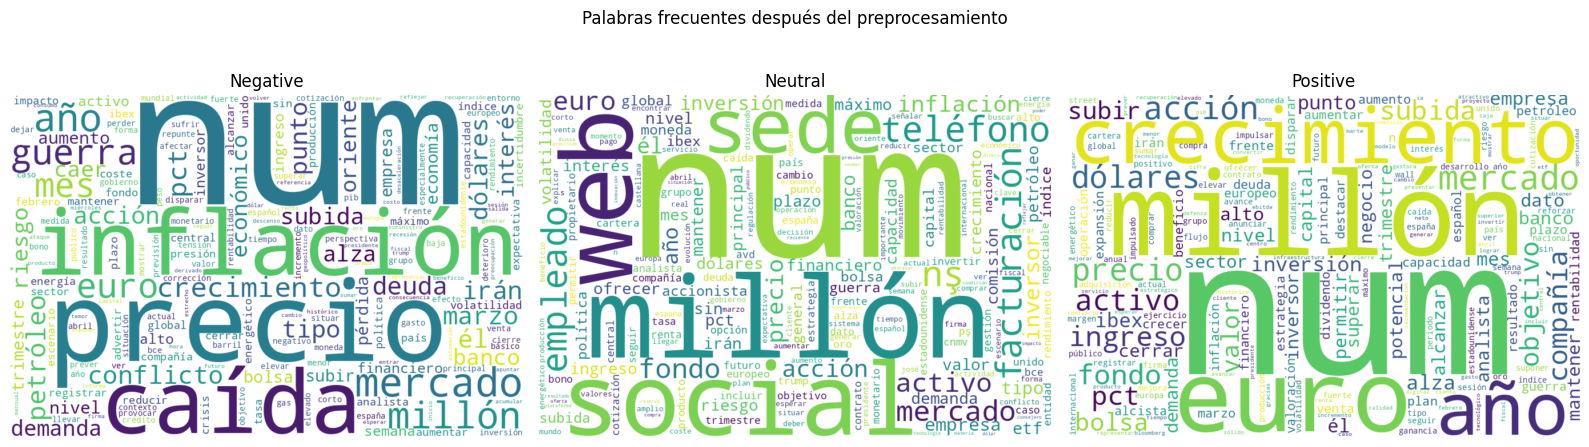

In [26]:
sentiment_order = ['negative', 'neutral', 'positive']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Palabras frecuentes después del preprocesamiento')

for ax, label in zip(axes, sentiment_order):
    corpus = ' '.join(
        data_clean.loc[
            data_clean['label'].eq(label),
            'sentence_clean'
        ].astype(str)
    )

    if corpus.strip():
        wc = WordCloud(
            width=900,
            height=600,
            background_color='white',
            collocations=False
        ).generate(corpus)

        ax.imshow(wc, interpolation='bilinear')

    ax.set_title(label.capitalize())
    ax.axis('off')

plt.tight_layout()
plt.show()


### **2.6. Exportación del corpus preparado**

En esta sección se exporta una versión que conserva tanto el texto original como el texto procesado. Esto
mejora la trazabilidad y evita tener que volver a construir el corpus desde cero durante las
siguientes fases.


In [28]:
output_columns = [
    'sentence_original',
    'sentence_clean',
    'label',
    'source',
    'language',
    'encoding_flag'
]

prepared_corpus = data_clean[output_columns].copy()
prepared_corpus.to_csv(
    'financial_sentiment_es_prepared.csv',
    index=False,
    encoding='utf-8'
)

print('Archivo generado: financial_sentiment_es_prepared.csv')
print('Dimensiones:', prepared_corpus.shape)
display(prepared_corpus.head())


Archivo generado: financial_sentiment_es_prepared.csv
Dimensiones: (7125, 6)


,sentence_original,sentence_clean,label,source,language,encoding_flag
32062,- Isdin abrirá un centro logístico de 22.000 m...,isdin abrir centro logístico num metro bunzl a...,positive,expansion_empresas,es,True
32063,MiiN Cosmetics dispara los ingresos y pisa el ...,miin cosmetics disparar ingreso pisa acelerado...,positive,expansion_empresas,es,False
32064,La subida del volumen de negocio coincidió con...,subida volumen negocio coincidir apertura num ...,positive,expansion_empresas,es,True
32065,La compańía barcelonesa entró el ańo pasado en...,compańía barcelonesa entrar ańo grecia firmar ...,neutral,expansion_empresas,es,True
32066,MiiN también abrió en 2025 un centro logístico...,miin abrir num centro logístico num metro cuad...,positive,expansion_empresas,es,True


### **2.7. Conclusiones del punto 2**

El corpus queda preparado mediante un flujo reproducible que:

- preserva el texto original
- normaliza Unicode sin eliminar arbitrariamente caracteres del español
- conserva negaciones relevantes para sentimiento
- mantiene la señal financiera de números, porcentajes y monedas
- utiliza `nlp.pipe()` para procesar textos por lotes
- evita sobrescribir la variable original
- controla que no se generen documentos vacíos
- verifica que la distribución de clases no cambie por efecto de la limpieza
- exporta un corpus preparado para la fase de modelado.

Las transformaciones que aprendan parámetros del corpus, por ejemplo TF-IDF, selección de características o balanceo de clases, deben ajustarse posteriormente solo con el conjunto de entrenamiento para evitar fuga de información.

## **3. Cierre de la Fase 2 y verificación de la rúbrica**

Con las secciones anteriores quedan cubiertos explícitamente los cuatro componentes de la entrega:

1. **Análisis exploratorio del corpus:** número de documentos, variables, memoria, distribución por idioma, delimitación del subconjunto en español, fuentes de procedencia (`source`), nulos, vacíos, duplicados e indicios de codificación.
2. **Análisis descriptivo:** inventario y tipo de cada variable, distribución y desbalance de la variable objetivo `label`, longitud en caracteres/palabras, Type-Token Ratio y legibilidad (Fernández-Huerta) como métrica descriptiva.
3. **Visualización de la información:** gráficos de barras (idioma, fuente, clases), histogramas (longitud, TTR, legibilidad), mapa de calor `source`–`label`, diagramas de caja por sentimiento, matriz de correlación de Spearman y nubes de palabras por clase.
4. **Limpieza / preprocesamiento NLP:** filtrado por criterios objetivos, normalización Unicode, tokenización y lematización con spaCy, eliminación conservadora de *stop words* con preservación de negaciones, marcadores `num`/`pct`/`moneda`, expresiones regulares y control posterior de documentos vacíos.

Además quedan documentadas decisiones que suelen quedar implícitas en un EDA: el tratamiento de `label` como variable **nominal de tres clases** (no ordinal), la cuantificación del desbalance, la exclusión de `source` y `language` como predictores de la línea base y la redundancia entre `caracteres` y `palabras`.

La siguiente celda consolida, directamente desde los datos, los indicadores finales de la fase y verifica que el archivo exportado sea consistente con el corpus en memoria.

In [29]:
# ------------------------------------------------------------------
# 3.1 Resumen consolidado de la Fase 2
# ------------------------------------------------------------------
n_total      = len(data)             # dataset multilingüe completo
n_es         = len(es_data)          # subconjunto en español
n_corrected  = len(data_corrected)   # tras filtros objetivos y deduplicación
n_final      = len(data_clean)       # tras preprocesamiento NLP
retained_pct = 100 * n_final / n_es if n_es else 0

phase2_summary = pd.DataFrame({
    'indicador': [
        'Documentos del dataset completo',
        'Documentos en español',
        'Documentos tras filtros objetivos y deduplicación',
        'Duplicados exactos eliminados',
        'Documentos eliminados por quedar vacíos tras limpieza',
        'Documentos finales del corpus preparado',
        'Porcentaje conservado respecto al corpus español',
        'Variables originales',
        'Variables en el corpus exportado',
        'Clases de la variable objetivo (label)',
        'Relación clase mayoritaria / minoritaria',
        'Documentos con bandera de codificación conservados',
        'V de Cramér (source, label)',
        '|rho| Spearman caracteres–palabras'
    ],
    'valor': [
        n_total,
        n_es,
        n_corrected,
        removed_duplicates,
        removed_after_preprocess,
        n_final,
        f'{retained_pct:.2f}%',
        data.shape[1],
        prepared_corpus.shape[1],
        data_clean['label'].nunique(),
        f'{imbalance_ratio:.2f}:1',
        int(data_clean['encoding_flag'].sum()),
        f'{cramers_v:.3f}',
        f'{abs(spearman_text.loc["caracteres", "palabras"]):.3f}'
    ]
})

display(phase2_summary)

# ------------------------------------------------------------------
# 3.2 Verificación de integridad del corpus exportado
# ------------------------------------------------------------------
reloaded = pd.read_csv('financial_sentiment_es_prepared.csv', encoding='utf-8')

integrity_checks = pd.Series({
    'Mismo número de filas que data_clean':
        len(reloaded) == n_final,
    'Columnas esperadas presentes':
        list(reloaded.columns) == output_columns,
    'Sin textos limpios vacíos':
        int(reloaded['sentence_clean'].fillna('').str.strip().eq('').sum()) == 0,
    'Solo las tres clases esperadas en label':
        set(reloaded['label'].unique()) == expected_labels,
    'Sin duplicados de sentence_original':
        int(reloaded.duplicated(subset=['sentence_original']).sum()) == 0,
    'Distribución de clases idéntica a la de memoria':
        reloaded['label'].value_counts().sort_index().equals(
            data_clean['label'].value_counts().sort_index()
        )
})

display(integrity_checks.to_frame('cumple'))
assert integrity_checks.all(), 'Alguna verificación de integridad falló; revisar la exportación.'
print('✔ El corpus exportado es consistente con el corpus en memoria.')

# ------------------------------------------------------------------
# 3.3 Checklist de la rúbrica
# ------------------------------------------------------------------
rubric_checklist = pd.DataFrame([
    {'componente': 'Análisis exploratorio del corpus',
     'evidencia': 'Tamaño, variables, memoria, idioma, fuentes, nulos, vacíos, duplicados, codificación',
     'seccion': '1.1 – 1.2', 'estado': 'Cubierto'},
    {'componente': 'Análisis descriptivo de variables',
     'evidencia': 'Catálogo de variables, distribución y desbalance de label, longitud, TTR, legibilidad',
     'seccion': '1.2.4 – 1.3', 'estado': 'Cubierto'},
    {'componente': 'Relación entre variables / redundancia',
     'evidencia': 'V de Cramér source–label, boxplots por clase, Spearman entre medidas de longitud',
     'seccion': '1.4', 'estado': 'Cubierto'},
    {'componente': 'Visualización de la información',
     'evidencia': 'Barras, histogramas, mapas de calor, diagramas de caja, nubes de palabras',
     'seccion': '1.1 – 2.5', 'estado': 'Cubierto'},
    {'componente': 'Limpieza / preprocesamiento NLP',
     'evidencia': 'Normalización Unicode, tokenización, lematización, stop words, negaciones, marcadores financieros',
     'seccion': '2.1 – 2.2', 'estado': 'Cubierto'},
    {'componente': 'Validación del preprocesamiento',
     'evidencia': 'Ejemplos antes/después, auditoría de longitud y de distribución de clases',
     'seccion': '2.3 – 2.4', 'estado': 'Cubierto'},
    {'componente': 'Exportación reproducible',
     'evidencia': 'financial_sentiment_es_prepared.csv con texto original y procesado',
     'seccion': '2.6 – 3', 'estado': 'Cubierto'},
])

display(rubric_checklist)


,indicador,valor
0,Documentos del dataset completo,39829
1,Documentos en español,7125
2,Documentos tras filtros objetivos y deduplicación,7125
3,Duplicados exactos eliminados,0
4,Documentos eliminados por quedar vacíos tras l...,0
5,Documentos finales del corpus preparado,7125
6,Porcentaje conservado respecto al corpus español,100.00%
7,Variables originales,4
8,Variables en el corpus exportado,6
9,Clases de la variable objetivo (label),3


,cumple
Mismo número de filas que data_clean,True
Columnas esperadas presentes,True
Sin textos limpios vacíos,True
Solo las tres clases esperadas en label,True
Sin duplicados de sentence_original,True
Distribución de clases idéntica a la de memoria,True


✔ El corpus exportado es consistente con el corpus en memoria.


,componente,evidencia,seccion,estado
0,Análisis exploratorio del corpus,"Tamaño, variables, memoria, idioma, fuentes, n...",1.1 – 1.2,Cubierto
1,Análisis descriptivo de variables,"Catálogo de variables, distribución y desbalan...",1.2.4 – 1.3,Cubierto
2,Relación entre variables / redundancia,"V de Cramér source–label, boxplots por clase, ...",1.4,Cubierto
3,Visualización de la información,"Barras, histogramas, mapas de calor, diagramas...",1.1 – 2.5,Cubierto
4,Limpieza / preprocesamiento NLP,"Normalización Unicode, tokenización, lematizac...",2.1 – 2.2,Cubierto
5,Validación del preprocesamiento,"Ejemplos antes/después, auditoría de longitud ...",2.3 – 2.4,Cubierto
6,Exportación reproducible,financial_sentiment_es_prepared.csv con texto ...,2.6 – 3,Cubierto


### **3.1. Conclusiones de la Fase 2**

Durante esta fase se completó el entendimiento y la preparación del corpus que servirá de base para el proyecto de análisis de sentimiento en noticias económicas. A partir del dataset multilingüe *Multilingual Financial Sentiment*, se delimitó el subconjunto en español, se caracterizó su estructura y calidad, y se construyó un corpus limpio, deduplicado y preprocesado, conservando en todo momento el texto original con el fin de garantizar la trazabilidad de cada transformación aplicada.

El análisis exploratorio permitió establecer la dimensión del corpus, su composición por idioma y por fuente de procedencia, así como la presencia de valores nulos, textos vacíos, duplicados exactos e indicios de problemas de codificación. Los filtros aplicados se limitaron a criterios objetivos y verificables (texto no vacío, etiqueta válida, idioma español y eliminación de duplicados), evitando deliberadamente el uso de umbrales de legibilidad como criterio de exclusión. Esta decisión reduce el riesgo de alterar de manera artificial la distribución de fuentes y sentimientos del corpus, asi como los documentos con posibles artefactos de codificación se conservaron y quedaron identificados mediante una bandera de control para su tratamiento en el preprocesamiento.

En cuanto a la variable objetivo, la etiqueta de sentimiento `label` se modela como una variable nominal de tres clases (`negative`, `neutral` y `positive`). El desbalance entre clases fue cuantificado mediante la razón entre la clase mayoritaria y la minoritaria, cuyo valor se reporta en el resumen consolidado de la sección 3.1. Este resultado implica que la evaluación de los modelos en la fase siguiente deberá incorporar métricas robustas al desbalance, como el **F1 macro**, y no limitarse a la exactitud global.

El estudio de relaciones entre variables aportó dos hallazgos relevantes para el modelado. En primer lugar, la variable `source` presenta asociación con la etiqueta de sentimiento, según el V de Cramér calculado en la sección 1.4. Por ello se decidió mantenerla como variable de auditoría y excluirla como predictor de la línea base, con el propósito de evitar que el clasificador aprenda patrones editoriales de una fuente en lugar del sentimiento expresado en el texto. En segundo lugar, se identificaron redundancias estructurales: la variable `language` es constante una vez filtrado el español, y las medidas de longitud en caracteres y en palabras presentan una correlación de Spearman elevada, por lo que basta con conservar una de ellas en caso de utilizarlas como características auxiliares.

El preprocesamiento se diseñó de forma coherente con la naturaleza financiera del corpus. Se aplicó normalización Unicode, tokenización y lematización con spaCy, conversión a minúsculas con conservación de los caracteres propios del español y eliminación conservadora de *stop words*. De manera explícita se preservaron las negaciones, dado que pueden invertir la polaridad de una oración, y se representaron los números, porcentajes y símbolos monetarios mediante los marcadores `num`, `pct` y `moneda`, puesto que constituyen señales informativas en noticias económicas. No se realizó corrección ortográfica automática para no alterar nombres de empresas, productos o entidades. La validación cuantitativa confirmó que el preprocesamiento no generó documentos vacíos y que la distribución de clases se mantuvo estable antes y después de la limpieza.

**Entregable de esta fase:** `financial_sentiment_es_prepared.csv`, que contiene el texto original, el texto procesado, la etiqueta de sentimiento, la fuente, el idioma y la bandera de codificación. Su consistencia con el corpus en memoria fue verificada mediante controles de integridad sobre el número de filas, las columnas esperadas, la ausencia de textos vacíos y duplicados, y la coincidencia de la distribución de clases.

**Hacia la Fase 3,  el modelado:** toda transformación que aprenda parámetros a partir del corpus, tales como la vectorización TF-IDF, los embeddings ajustados, la selección de características o las técnicas de balanceo de clases, deberá ajustarse **únicamente sobre el conjunto de entrenamiento**, reutilizando el mismo flujo de preprocesamiento definido en la sección 2. De este modo se evita la fuga de información y se asegura una evaluación fiable del desempeño de los modelos.

## **Referencias:**


---



[1] Kenpache. *Multilingual Financial Sentiment* (dataset). Hugging Face. https://huggingface.co/datasets/Kenpache/multilingual-financial-sentiment

[2] Explosion AI. *spaCy: Industrial-strength Natural Language Processing*. https://spacy.io/

[3] spacy-langdetect. https://github.com/Abhijit-2592/spacy-langdetect

[4] Textstat: índice de legibilidad de Fernández-Huerta. https://www.spanishreadability.com/fernandez-huerta-readability-index

[5] Coeficiente de correlación de Spearman. https://www.sciencedirect.com/topics/mathematics/spearman-rank-correlation-coefficient

[6] V de Cramér (asociación entre variables categóricas). https://en.wikipedia.org/wiki/Cram%C3%A9r%27s_V

[7] Correlación de Pearson. https://www.sciencedirect.com/topics/computer-science/pearson-correlation

## **Créditos**

* **Profesores:** [Felipe Restrepo Calle](https://ferestrepoca.github.io/), [Elizabeth León Guzman](https://midas.unal.edu.co)
* **Asistentes docentes:**
    - [Juan Sebastián Malagón Torres](https://co.linkedin.com/in/juan-sebastian-malag%C3%B3n-torres-86039a164).
* **Diseño de imágenes:**
    - [Sebastián Daniel Moreno Martinez](http://www.linkedin.com/in/sm-xwx).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*